# Question-1: Image Denoising using Denoising Autoencoder (DAE)
**Dataset:** The Berkeley Segmentation Dataset and Benchmark (BSDS500)

This notebook demonstrates the end-to-end pipeline for training and evaluating a Convolutional Denoising Autoencoder (ConvDAE) on BSDS500 images corrupted with **Gaussian noise** and **Salt-and-Pepper noise**.

### Pipeline Overview:
1. **Dataset Preparation:** BSDS500 download, normalization to $[0, 1]$, and train/val/test splits (200/100/200).
2. **Noise Injection:** Gaussian noise $\mathcal{N}(0, \sigma^2)$ and Salt-and-Pepper impulse noise.
3. **Model Architecture:** Convolutional encoder-bottleneck-decoder with configurable bottleneck capacity.
4. **Training:** Supervised reconstruction under MSE / SSIM loss with Cosine Annealing learning rate.
5. **Evaluation & Visualization:** Quantitative metrics (MSE, PSNR, SSIM) + side-by-side triplet visualizer.
6. **Experimental Study:** Systematic analysis across noise levels and bottleneck dimensions.

**Submitting:** the graded record is this notebook *with its outputs*. In Colab, open Edit → Notebook settings and make sure "Omit code cell output when saving" is **off**. When everything has run, use File → Download → .ipynb and replace `colab_run.ipynb` in the repo with it. Training logs are also written to Drive, and the *Full log* cells below print them into the notebook, so a run split across several sessions still appears in full.

**Run all:** Runtime → Run all runs the whole notebook start to finish, in about 2–2.5 hours on a T4. The only interaction is the Google Drive permission popup at the start. Keep the tab open while it runs. If a step fails, the cell right after it stops with a message saying which step.

In [ ]:
from google.colab import drive, userdata
drive.mount('/content/drive')
!git clone https://github.com/uShaukat3737/genAiA2.git /content/drive/MyDrive/as2

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into '/content/drive/MyDrive/as2'...
remote: Enumerating objects: 113, done.
remote: Counting objects: 100% (113/113), done.
remote: Compressing objects: 100% (82/82), done.
remote: Total 113 (delta 44), reused 92 (delta 28), pack-reused 0 (from 0)
Receiving objects: 100% (113/113), 985.50 KiB | 10.37 MiB/s, done.
Resolving deltas: 100% (44/44), done.


## 1. Environment & GPU Acceleration Check

In [ ]:
!nvidia-smi

import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name:     {torch.cuda.get_device_name(0)}")
assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU, then Run all again"

Mon Oct 12 13:01:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Mount Drive and enter the code folder
Upload this `q1/` folder to `MyDrive/as2/q1` first. Checkpoints, results and the dataset are written inside it, so they survive a disconnect.

Each script's console output is also appended to `logs/<step>.log` here on Drive, so it survives a disconnect.

In [ ]:
from google.colab import drive; drive.mount('/content/drive')
%cd /content/drive/MyDrive/as2/q1
!mkdir -p logs

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/as2/q1


## 2. Install Dependencies

In [ ]:
!pip install -r requirements.txt

## 3. Dataset Preparation & Noise Injection (Tasks 1 & 2)
Download the Berkeley Segmentation Dataset (BSDS500) and verify artificial noise injection.

[Dataset] Downloading BSDS500 archive from GitHub mirror...
[Dataset] Download complete (160.04 MB). Extracting...
[Dataset] Extracted BSDS500 images to: /content/drive/MyDrive/as2/q1/data/BSDS500
          Counts -> Train: 200, Val: 100, Test: 200
Testing DataLoader on ./data/BSDS500...
Loaded train batch successfully! Noisy shape: torch.Size([4, 3, 128, 128]), Clean shape: torch.Size([4, 3, 128, 128])
Noisy min: 0.000, max: 1.000
Clean min: 0.000, max: 1.000
Saved sample comparison to ./sample_noise.png


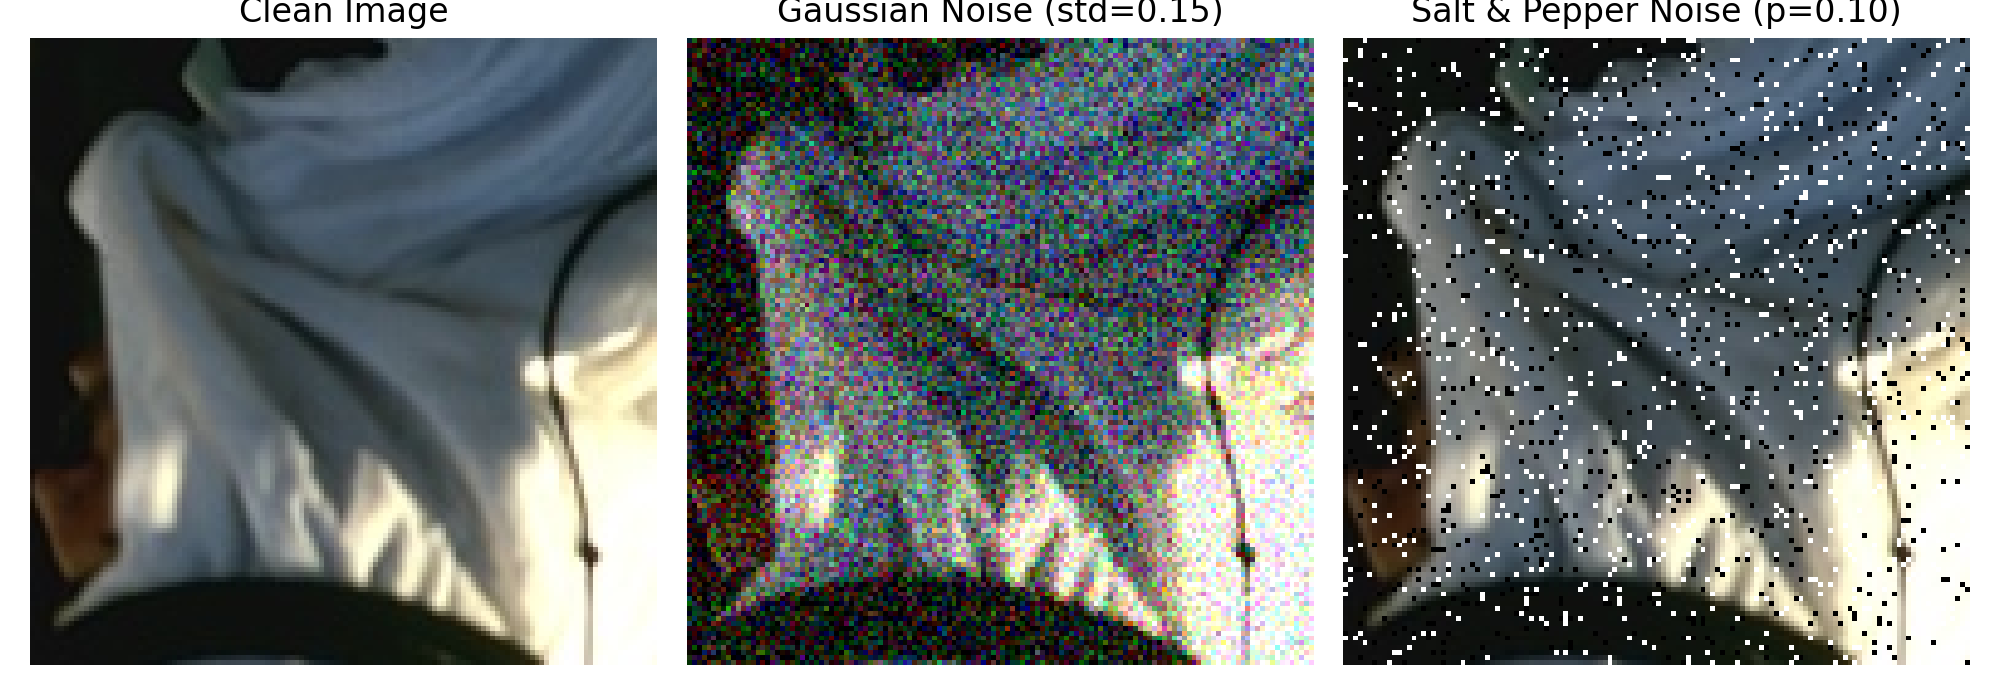

In [ ]:
!python -u dataset.py --download --data_dir ./data/BSDS500 --save_sample ./sample_noise.png 2>&1 | tee -a logs/dataset.log

from IPython.display import Image, display
display(Image('./sample_noise.png'))

## 4. DAE Architecture Inspection (Task 3)
Inspect the Convolutional Denoising Autoencoder with customizable bottleneck compression.

In [ ]:
!python -u models.py --bottleneck 32 2>&1 | tee -a logs/models.log

Model instantiated successfully!
Input shape:  torch.Size([2, 3, 128, 128])
Latent shape: (32, 32, 32) (32768 elements)
Output shape: torch.Size([2, 3, 128, 128])
Compression ratio: 1.50x
Total parameters: 171,523


## 5. Model Training (Task 4)
Train ConvDAE models under both Gaussian noise and Salt-and-Pepper noise.

In [ ]:
# Train on Gaussian Noise (std = 0.15)
!python -u train.py \
  --data_dir ./data/BSDS500 \
  --noise_type gaussian \
  --noise_param 0.15 \
  --bottleneck 32 \
  --loss mse \
  --epochs 35 \
  --batch_size 16 \
  --lr 0.001 2>&1 | tee -a logs/train_gaussian.log
import os
assert os.path.exists("./checkpoints/dae_gaussian_p0.15_btn32_mse/best_model.pth"), "training failed: see the output above"

 Starting Denoising Autoencoder Training
 Device:         cuda
 Noise Type:     gaussian (param=0.15)
 Bottleneck Ch:  32
 Loss Function:  mse
 Epochs:         35 | Batch Size: 16 | LR: 0.001
[Model] Latent shape: (32, 32, 32), Parameters: 171,523
Epoch [01/35] Train Loss: 0.01301 | Val Loss: 0.00915 | Val PSNR: 20.99 dB | Val SSIM: 0.5928 | Time: 18.1s
Epoch [02/35] Train Loss: 0.00822 | Val Loss: 0.00761 | Val PSNR: 21.98 dB | Val SSIM: 0.6337 | Time: 13.6s
Epoch [03/35] Train Loss: 0.00770 | Val Loss: 0.00593 | Val PSNR: 23.00 dB | Val SSIM: 0.6639 | Time: 13.4s
Epoch [04/35] Train Loss: 0.00645 | Val Loss: 0.00721 | Val PSNR: 22.06 dB | Val SSIM: 0.6830 | Time: 13.6s
Epoch [05/35] Train Loss: 0.00615 | Val Loss: 0.00546 | Val PSNR: 23.24 dB | Val SSIM: 0.6844 | Time: 12.5s
Epoch [06/35] Train Loss: 0.00585 | Val Loss: 0.00782 | Val PSNR: 21.51 dB | Val SSIM: 0.6879 | Time: 12.6s
Epoch [07/35] Train Loss: 0.00577 | Val Loss: 0.00500 | Val PSNR: 23.68 dB | Val SSIM: 0.7180 | Time: 12

In [ ]:
# Train on Salt-and-Pepper Noise (corruption ratio p = 0.10)
!python -u train.py \
  --data_dir ./data/BSDS500 \
  --noise_type salt_and_pepper \
  --noise_param 0.10 \
  --bottleneck 32 \
  --loss mse \
  --epochs 35 \
  --batch_size 16 \
  --lr 0.001 2>&1 | tee -a logs/train_salt_and_pepper.log
import os
assert os.path.exists("./checkpoints/dae_salt_and_pepper_p0.1_btn32_mse/best_model.pth"), "training failed: see the output above"

 Starting Denoising Autoencoder Training
 Device:         cuda
 Noise Type:     salt_and_pepper (param=0.1)
 Bottleneck Ch:  32
 Loss Function:  mse
 Epochs:         35 | Batch Size: 16 | LR: 0.001
[Model] Latent shape: (32, 32, 32), Parameters: 171,523
Epoch [01/35] Train Loss: 0.01329 | Val Loss: 0.00926 | Val PSNR: 21.07 dB | Val SSIM: 0.5621 | Time: 14.0s
Epoch [02/35] Train Loss: 0.00874 | Val Loss: 0.00777 | Val PSNR: 21.82 dB | Val SSIM: 0.6136 | Time: 13.3s
Epoch [03/35] Train Loss: 0.00755 | Val Loss: 0.00789 | Val PSNR: 21.63 dB | Val SSIM: 0.6358 | Time: 13.2s
Epoch [04/35] Train Loss: 0.00664 | Val Loss: 0.00642 | Val PSNR: 22.65 dB | Val SSIM: 0.6853 | Time: 12.9s
Epoch [05/35] Train Loss: 0.00663 | Val Loss: 0.00924 | Val PSNR: 20.94 dB | Val SSIM: 0.6921 | Time: 12.3s
Epoch [06/35] Train Loss: 0.00650 | Val Loss: 0.01236 | Val PSNR: 19.51 dB | Val SSIM: 0.6664 | Time: 12.7s
Epoch [07/35] Train Loss: 0.00581 | Val Loss: 0.00647 | Val PSNR: 22.52 dB | Val SSIM: 0.7018 | Ti

### Full training logs (all sessions)
Prints the log files from Drive, so the record is complete even if a training cell was re-run after a disconnect.

In [ ]:
!cat logs/train_gaussian.log
!echo; echo '==================== salt and pepper ===================='; echo
!cat logs/train_salt_and_pepper.log

 Starting Denoising Autoencoder Training
 Device:         cuda
 Noise Type:     gaussian (param=0.15)
 Bottleneck Ch:  32
 Loss Function:  mse
 Epochs:         35 | Batch Size: 16 | LR: 0.001
[Model] Latent shape: (32, 32, 32), Parameters: 171,523
Epoch [01/35] Train Loss: 0.01301 | Val Loss: 0.00915 | Val PSNR: 20.99 dB | Val SSIM: 0.5928 | Time: 18.1s
Epoch [02/35] Train Loss: 0.00822 | Val Loss: 0.00761 | Val PSNR: 21.98 dB | Val SSIM: 0.6337 | Time: 13.6s
Epoch [03/35] Train Loss: 0.00770 | Val Loss: 0.00593 | Val PSNR: 23.00 dB | Val SSIM: 0.6639 | Time: 13.4s
Epoch [04/35] Train Loss: 0.00645 | Val Loss: 0.00721 | Val PSNR: 22.06 dB | Val SSIM: 0.6830 | Time: 13.6s
Epoch [05/35] Train Loss: 0.00615 | Val Loss: 0.00546 | Val PSNR: 23.24 dB | Val SSIM: 0.6844 | Time: 12.5s
Epoch [06/35] Train Loss: 0.00585 | Val Loss: 0.00782 | Val PSNR: 21.51 dB | Val SSIM: 0.6879 | Time: 12.6s
Epoch [07/35] Train Loss: 0.00577 | Val Loss: 0.00500 | Val PSNR: 23.68 dB | Val SSIM: 0.7180 | Time: 12

## 6. Evaluation & Triplet Visualizations (Task 5)
Evaluate reconstruction quality on the test split using MSE, PSNR, and SSIM.
Visualizations show:
- Row 1: Original clean ground truth
- Row 2: Corrupted noisy input image
- Row 3: Reconstructed denoised output image

 Evaluating Denoising Autoencoder on BSDS500 [TEST]
 Checkpoint:      best_model.pth
 Architecture:    Bottleneck=32, BaseChannels=32
 Noise Type:      gaussian (param=0.15)
 Device:          cuda

------------------- Evaluation Results --------------------
 Total Evaluated Images:  200
 Input (Noisy) MSE:       0.01976
 Input (Noisy) PSNR:      17.05 dB
 Input (Noisy) SSIM:      0.3537
 Output (Denoised) MSE:   0.00281
 Output (Denoised) PSNR:  26.00 dB
 Output (Denoised) SSIM:  0.7766
 PSNR Improvement:        +8.95 dB
 SSIM Improvement:        +0.4229
-----------------------------------------------------------
[Evaluation] Metrics saved to: results/metrics_best_model_gaussian_0.15.json
[Evaluation] Visualization grid saved to: results/visualization_best_model_gaussian_0.15.png


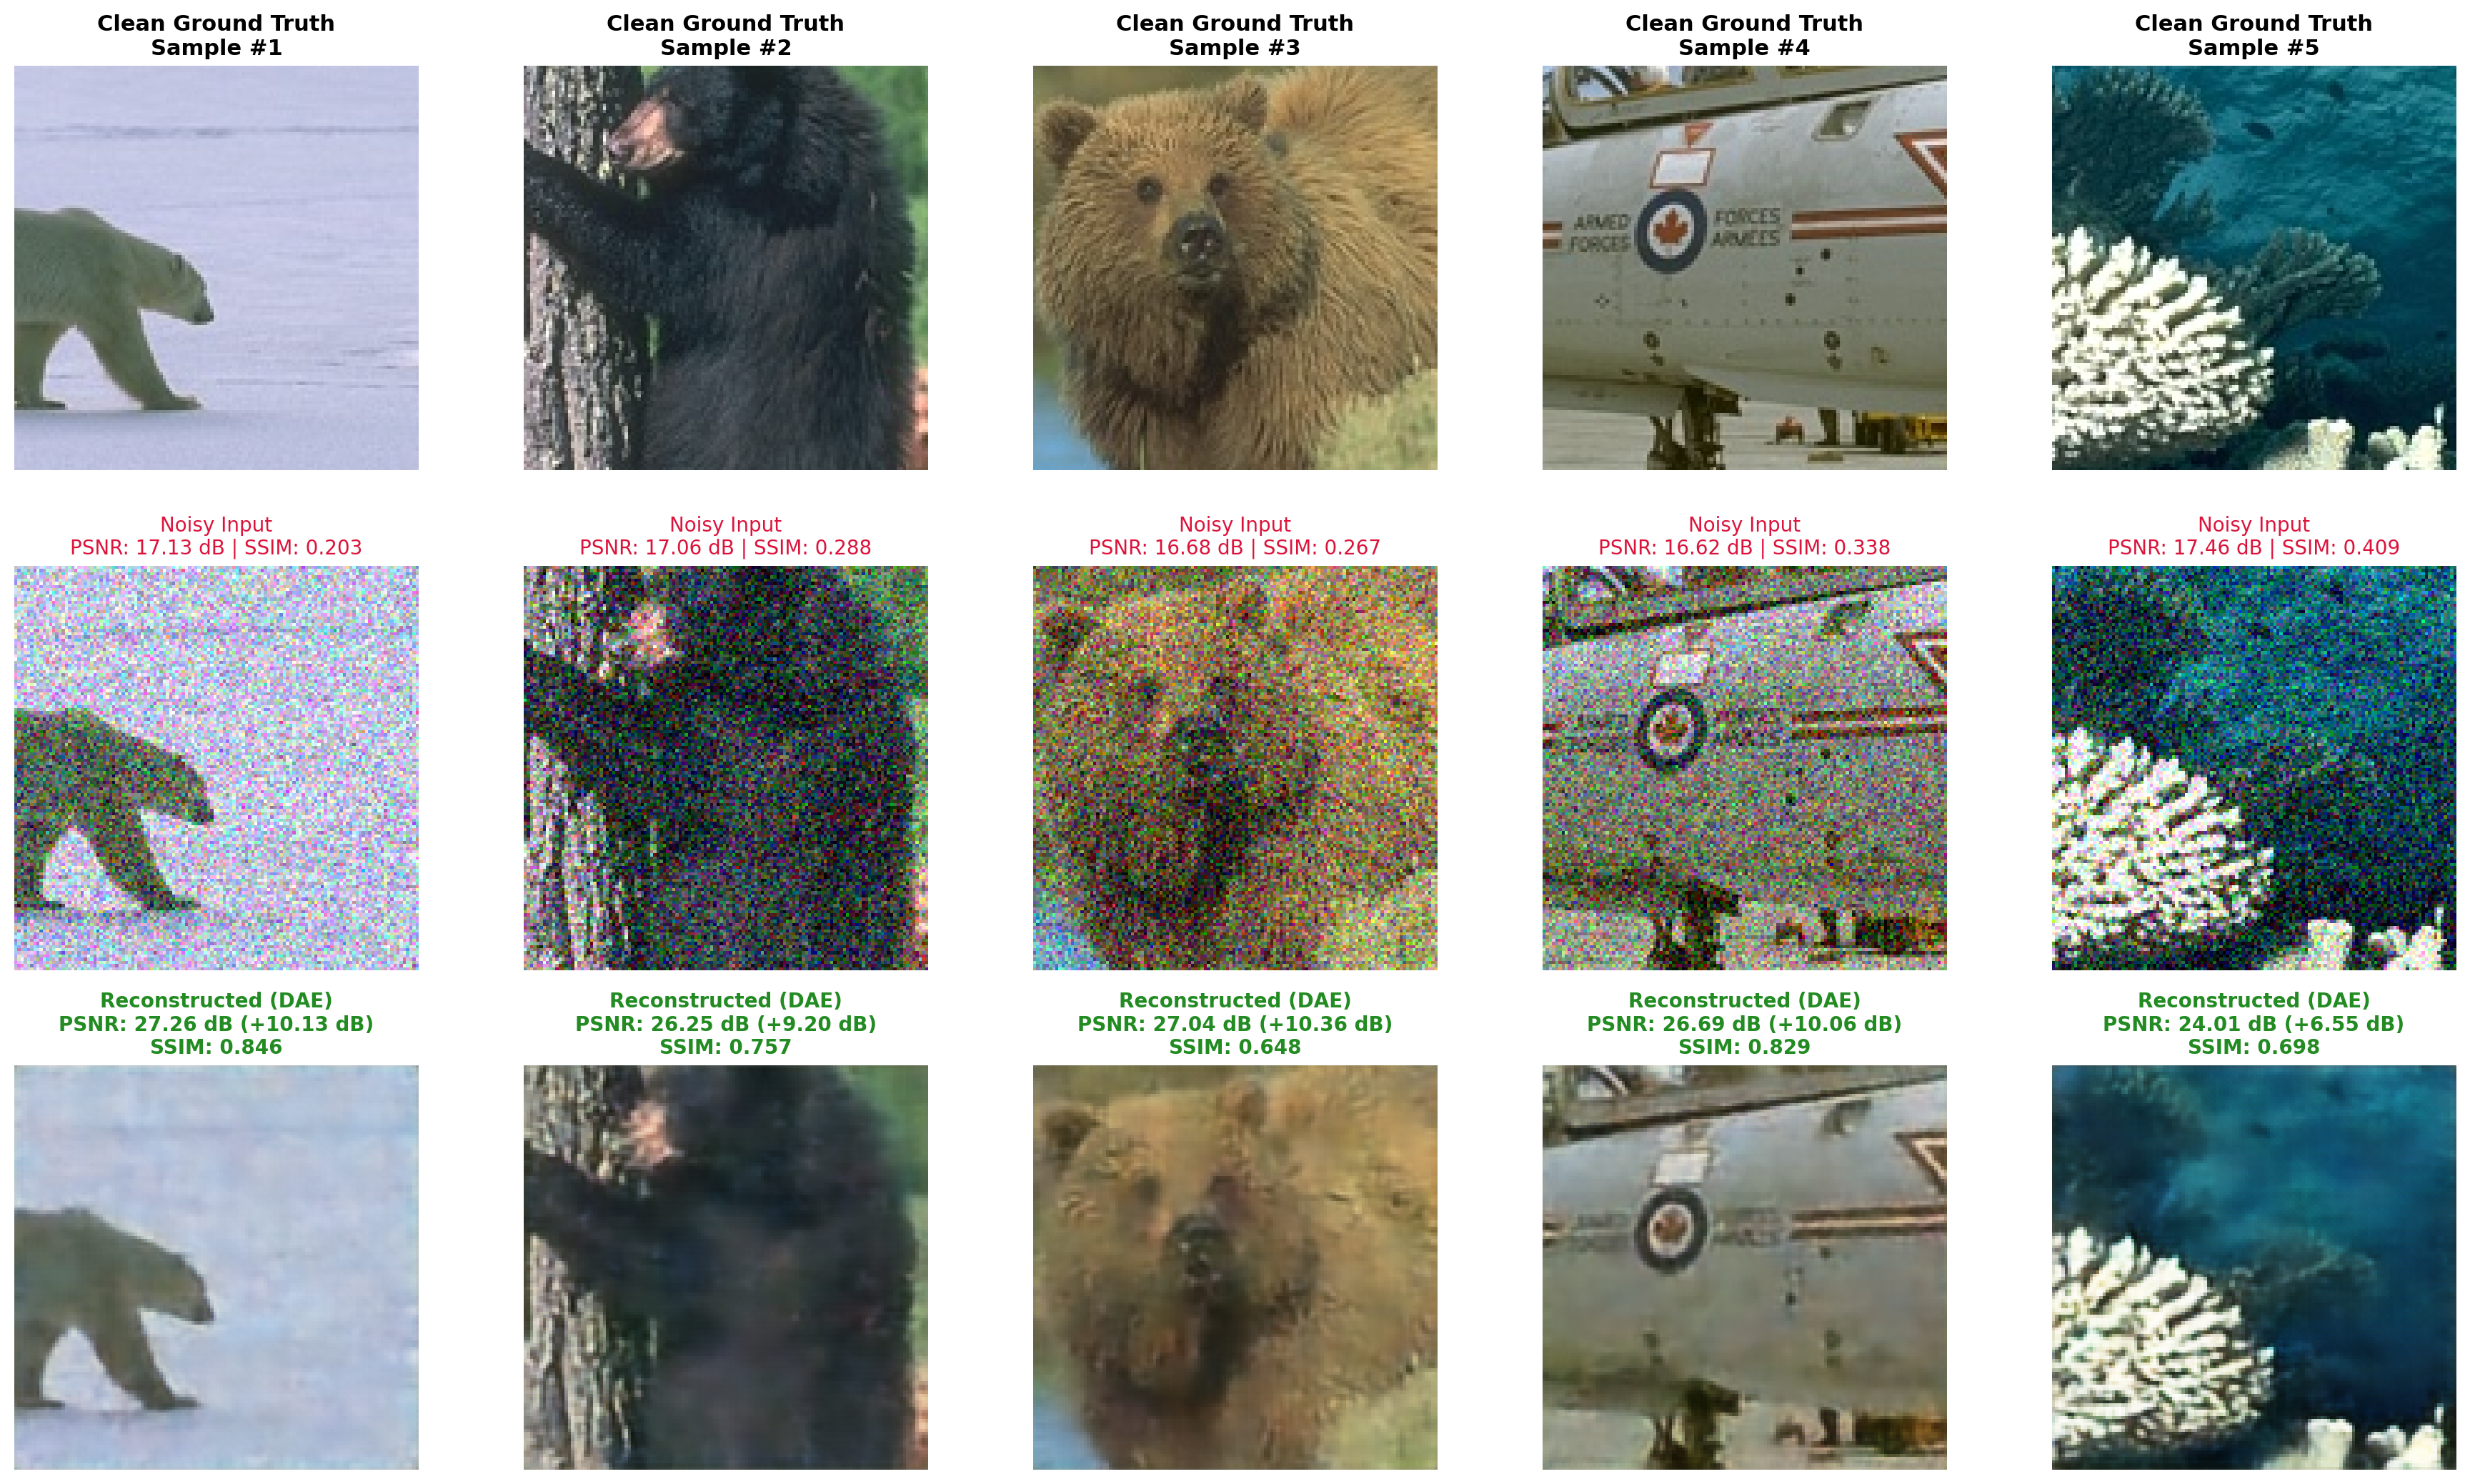

In [ ]:
# Evaluate Gaussian DAE on Test Split
!python -u evaluate.py \
  --checkpoint ./checkpoints/dae_gaussian_p0.15_btn32_mse/best_model.pth \
  --data_dir ./data/BSDS500 \
  --split test \
  --num_samples 5 \
  --save_dir ./results 2>&1 | tee -a logs/evaluate_gaussian.log

display(Image('./results/visualization_best_model_gaussian_0.15.png'))

 Evaluating Denoising Autoencoder on BSDS500 [TEST]
 Checkpoint:      best_model.pth
 Architecture:    Bottleneck=32, BaseChannels=32
 Noise Type:      salt_and_pepper (param=0.1)
 Device:          cuda

------------------- Evaluation Results --------------------
 Total Evaluated Images:  200
 Input (Noisy) MSE:       0.03183
 Input (Noisy) PSNR:      14.99 dB
 Input (Noisy) SSIM:      0.3360
 Output (Denoised) MSE:   0.00211
 Output (Denoised) PSNR:  27.66 dB
 Output (Denoised) SSIM:  0.8563
 PSNR Improvement:        +12.67 dB
 SSIM Improvement:        +0.5203
-----------------------------------------------------------
[Evaluation] Metrics saved to: results/metrics_best_model_salt_and_pepper_0.1.json
[Evaluation] Visualization grid saved to: results/visualization_best_model_salt_and_pepper_0.1.png


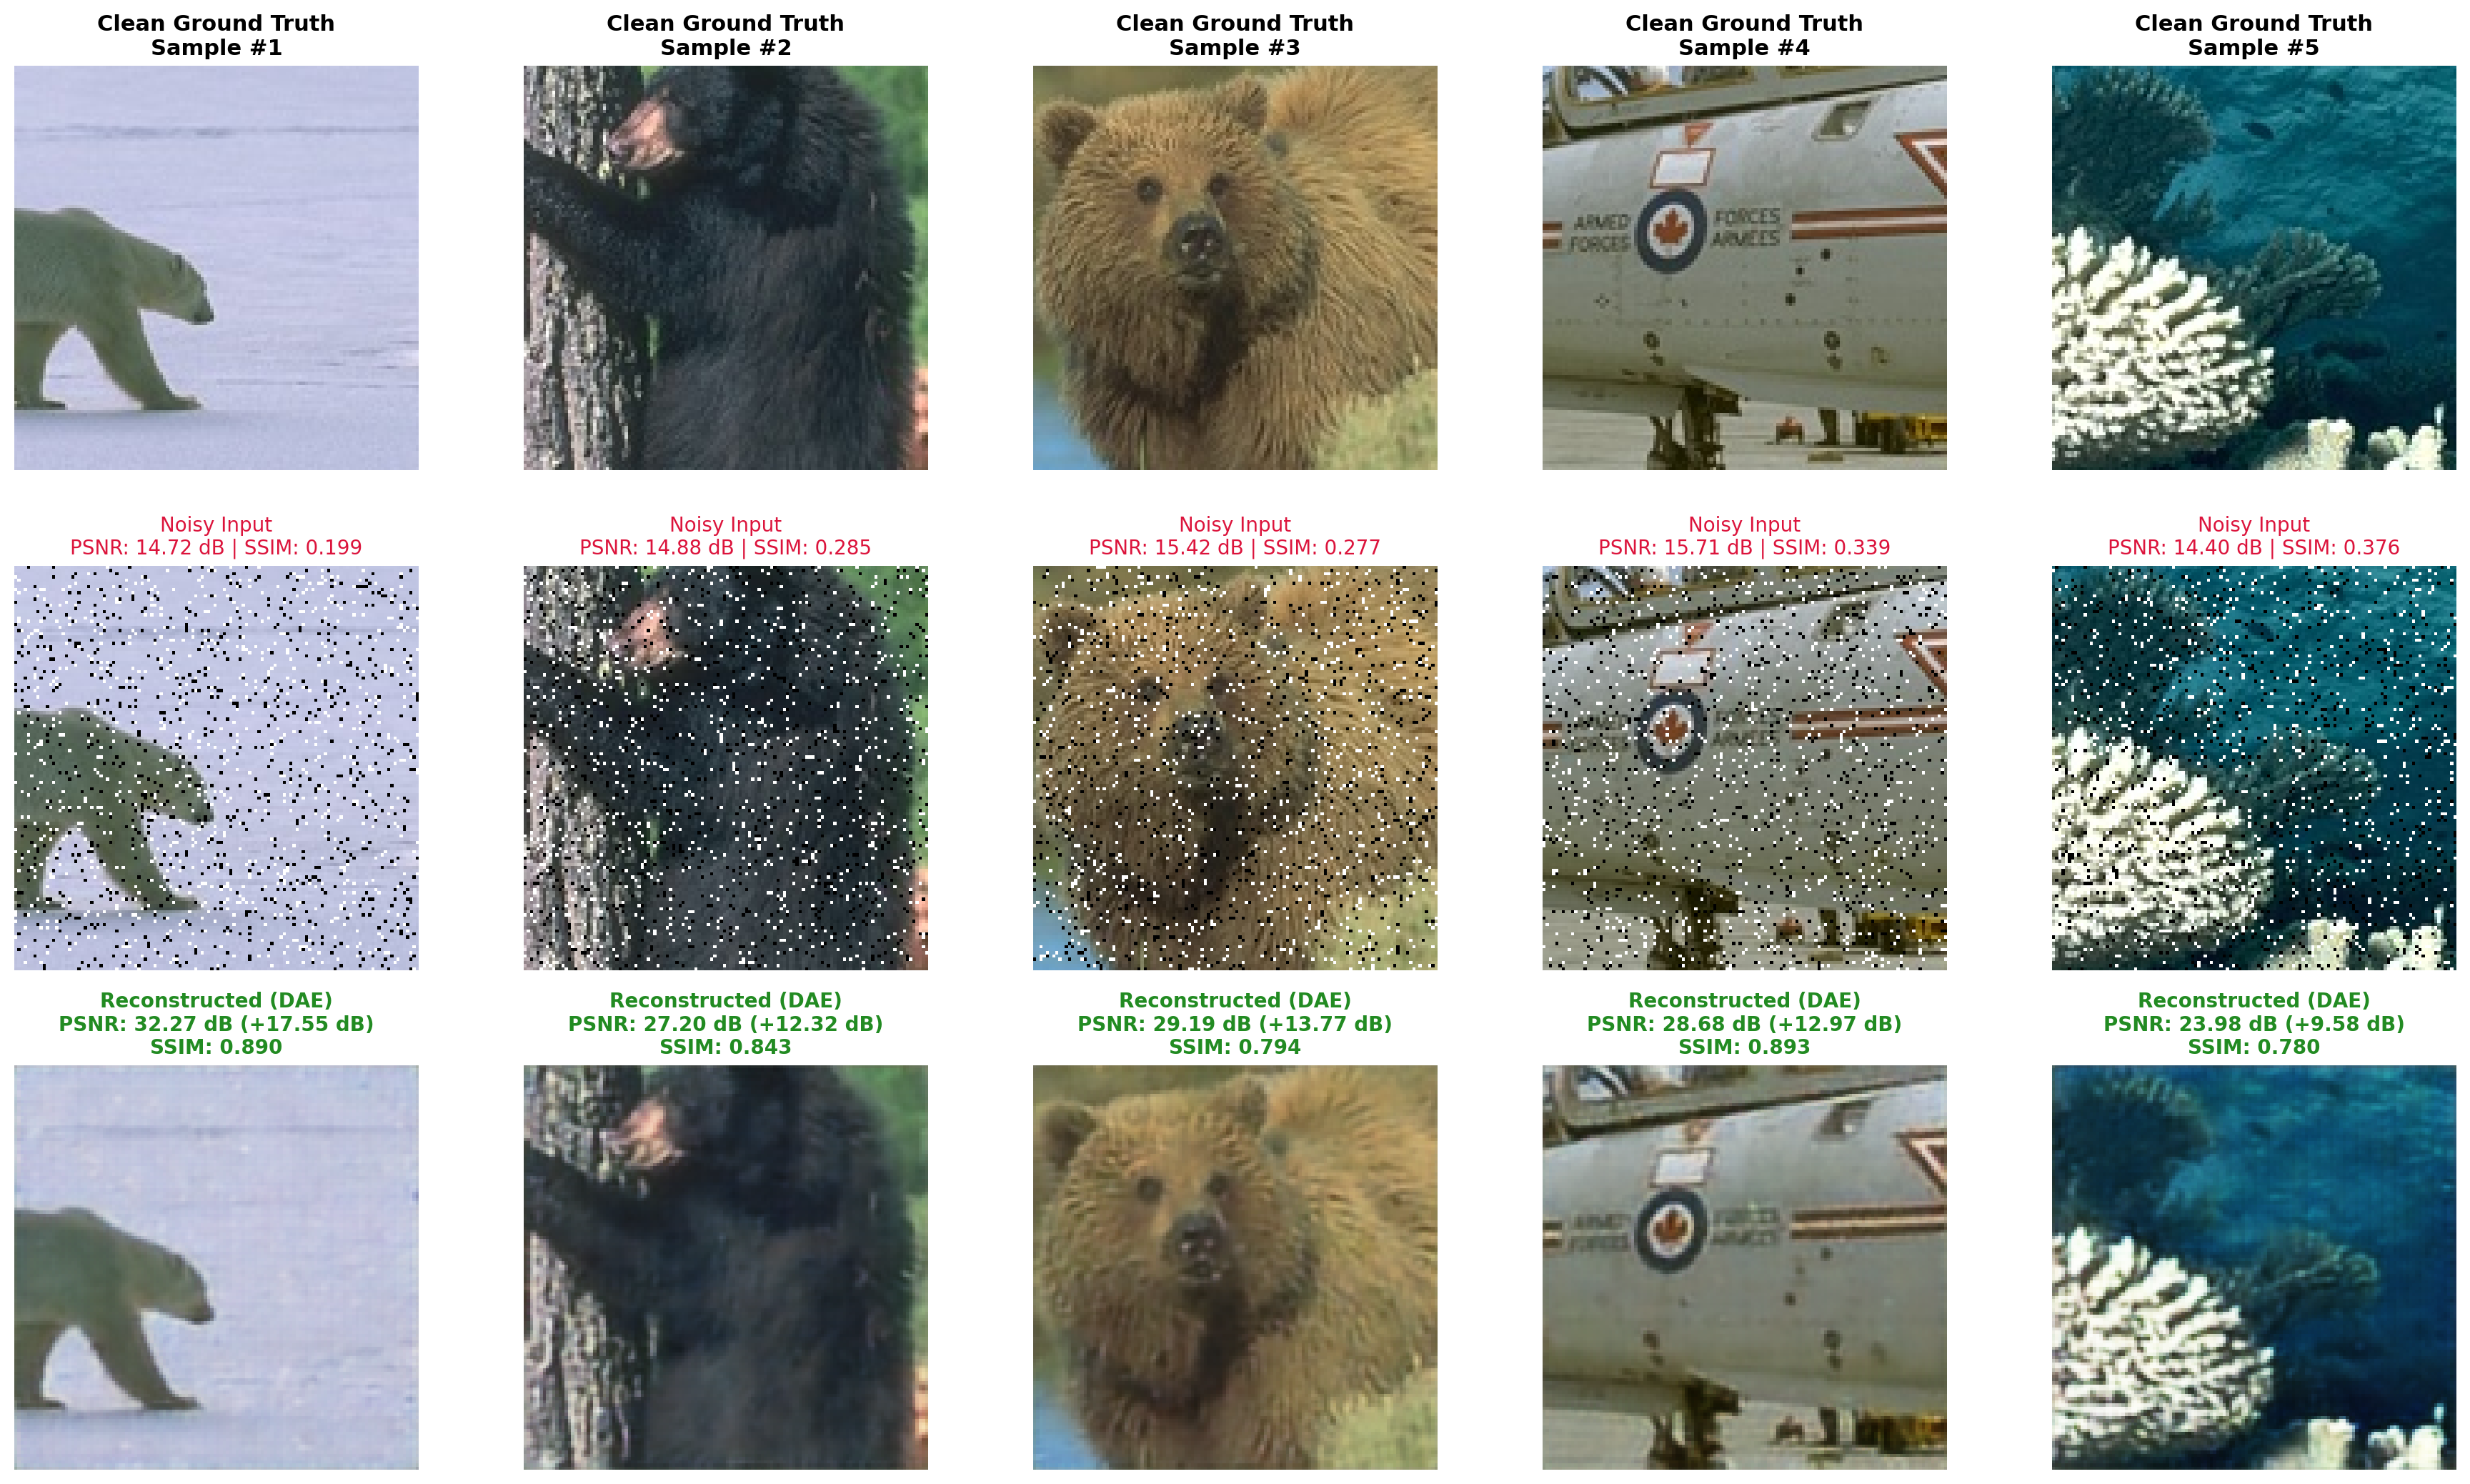

In [ ]:
# Evaluate Salt-and-Pepper DAE on Test Split
!python -u evaluate.py \
  --checkpoint ./checkpoints/dae_salt_and_pepper_p0.1_btn32_mse/best_model.pth \
  --data_dir ./data/BSDS500 \
  --split test \
  --num_samples 5 \
  --save_dir ./results 2>&1 | tee -a logs/evaluate_salt_and_pepper.log

display(Image('./results/visualization_best_model_salt_and_pepper_0.1.png'))

## 7. Experimental Study (Task 6)
Analyze reconstruction performance as a function of:
1. **Noise Intensity:** Gaussian ($\sigma \in [0.05, 0.10, 0.20, 0.30]$) and Salt-and-Pepper ($p \in [0.02, 0.05, 0.10, 0.20]$)
2. **Bottleneck Capacity:** Channel widths $\in [8, 16, 32, 64, 128]$

In [20]:
# Run complete experimental sweep
!python -u experiments.py \
  --data_dir ./data/BSDS500 \
  --output_dir ./experiments_output \
  --epochs 20 \
  --batch_size 16 2>&1 | tee -a logs/experiments.log
import os
assert os.path.exists("./experiments_output/experimental_study_report.md"), "experiment sweep failed: see the output above"

Running Experimental Study on Device: cuda

 [STUDY 1] Analyzing Reconstruction Performance vs Noise Levels

---> Training & Evaluating: Gaussian (std=0.05) | Bottleneck: 32 channels
Saved results table to: experiments_output/noise_study_results.csv
     Input PSNR: 26.19 dB -> Output PSNR: 27.12 dB (+0.92 dB)
     Input SSIM: 0.7115 -> Output SSIM: 0.8350 (+0.1234)

---> Training & Evaluating: Gaussian (std=0.10) | Bottleneck: 32 channels
Saved results table to: experiments_output/noise_study_results.csv
     Input PSNR: 20.35 dB -> Output PSNR: 26.08 dB (+5.73 dB)
     Input SSIM: 0.4834 -> Output SSIM: 0.7875 (+0.3041)

---> Training & Evaluating: Gaussian (std=0.20) | Bottleneck: 32 channels
Saved results table to: experiments_output/noise_study_results.csv
     Input PSNR: 14.83 dB -> Output PSNR: 24.53 dB (+9.70 dB)
     Input SSIM: 0.2733 -> Output SSIM: 0.7069 (+0.4335)

---> Training & Evaluating: Gaussian (std=0.30) | Bottleneck: 32 channels
Saved results table to: experiment

### Full experiment log (all sessions)

In [21]:
!cat logs/experiments.log

Running Experimental Study on Device: cuda

 [STUDY 1] Analyzing Reconstruction Performance vs Noise Levels

---> Training & Evaluating: Gaussian (std=0.05) | Bottleneck: 32 channels
Saved results table to: experiments_output/noise_study_results.csv
     Input PSNR: 26.19 dB -> Output PSNR: 27.15 dB (+0.96 dB)
     Input SSIM: 0.7115 -> Output SSIM: 0.8332 (+0.1217)

---> Training & Evaluating: Gaussian (std=0.10) | Bottleneck: 32 channels
Running Experimental Study on Device: cuda

 [STUDY 1] Analyzing Reconstruction Performance vs Noise Levels

---> Training & Evaluating: Gaussian (std=0.05) | Bottleneck: 32 channels
Saved results table to: experiments_output/noise_study_results.csv
     Input PSNR: 26.19 dB -> Output PSNR: 27.12 dB (+0.92 dB)
     Input SSIM: 0.7115 -> Output SSIM: 0.8350 (+0.1234)

---> Training & Evaluating: Gaussian (std=0.10) | Bottleneck: 32 channels
Saved results table to: experiments_output/noise_study_results.csv
     Input PSNR: 20.35 dB -> Output PSNR: 26.

### View Experimental Study Curves

Study 1: Performance vs Noise Levels:


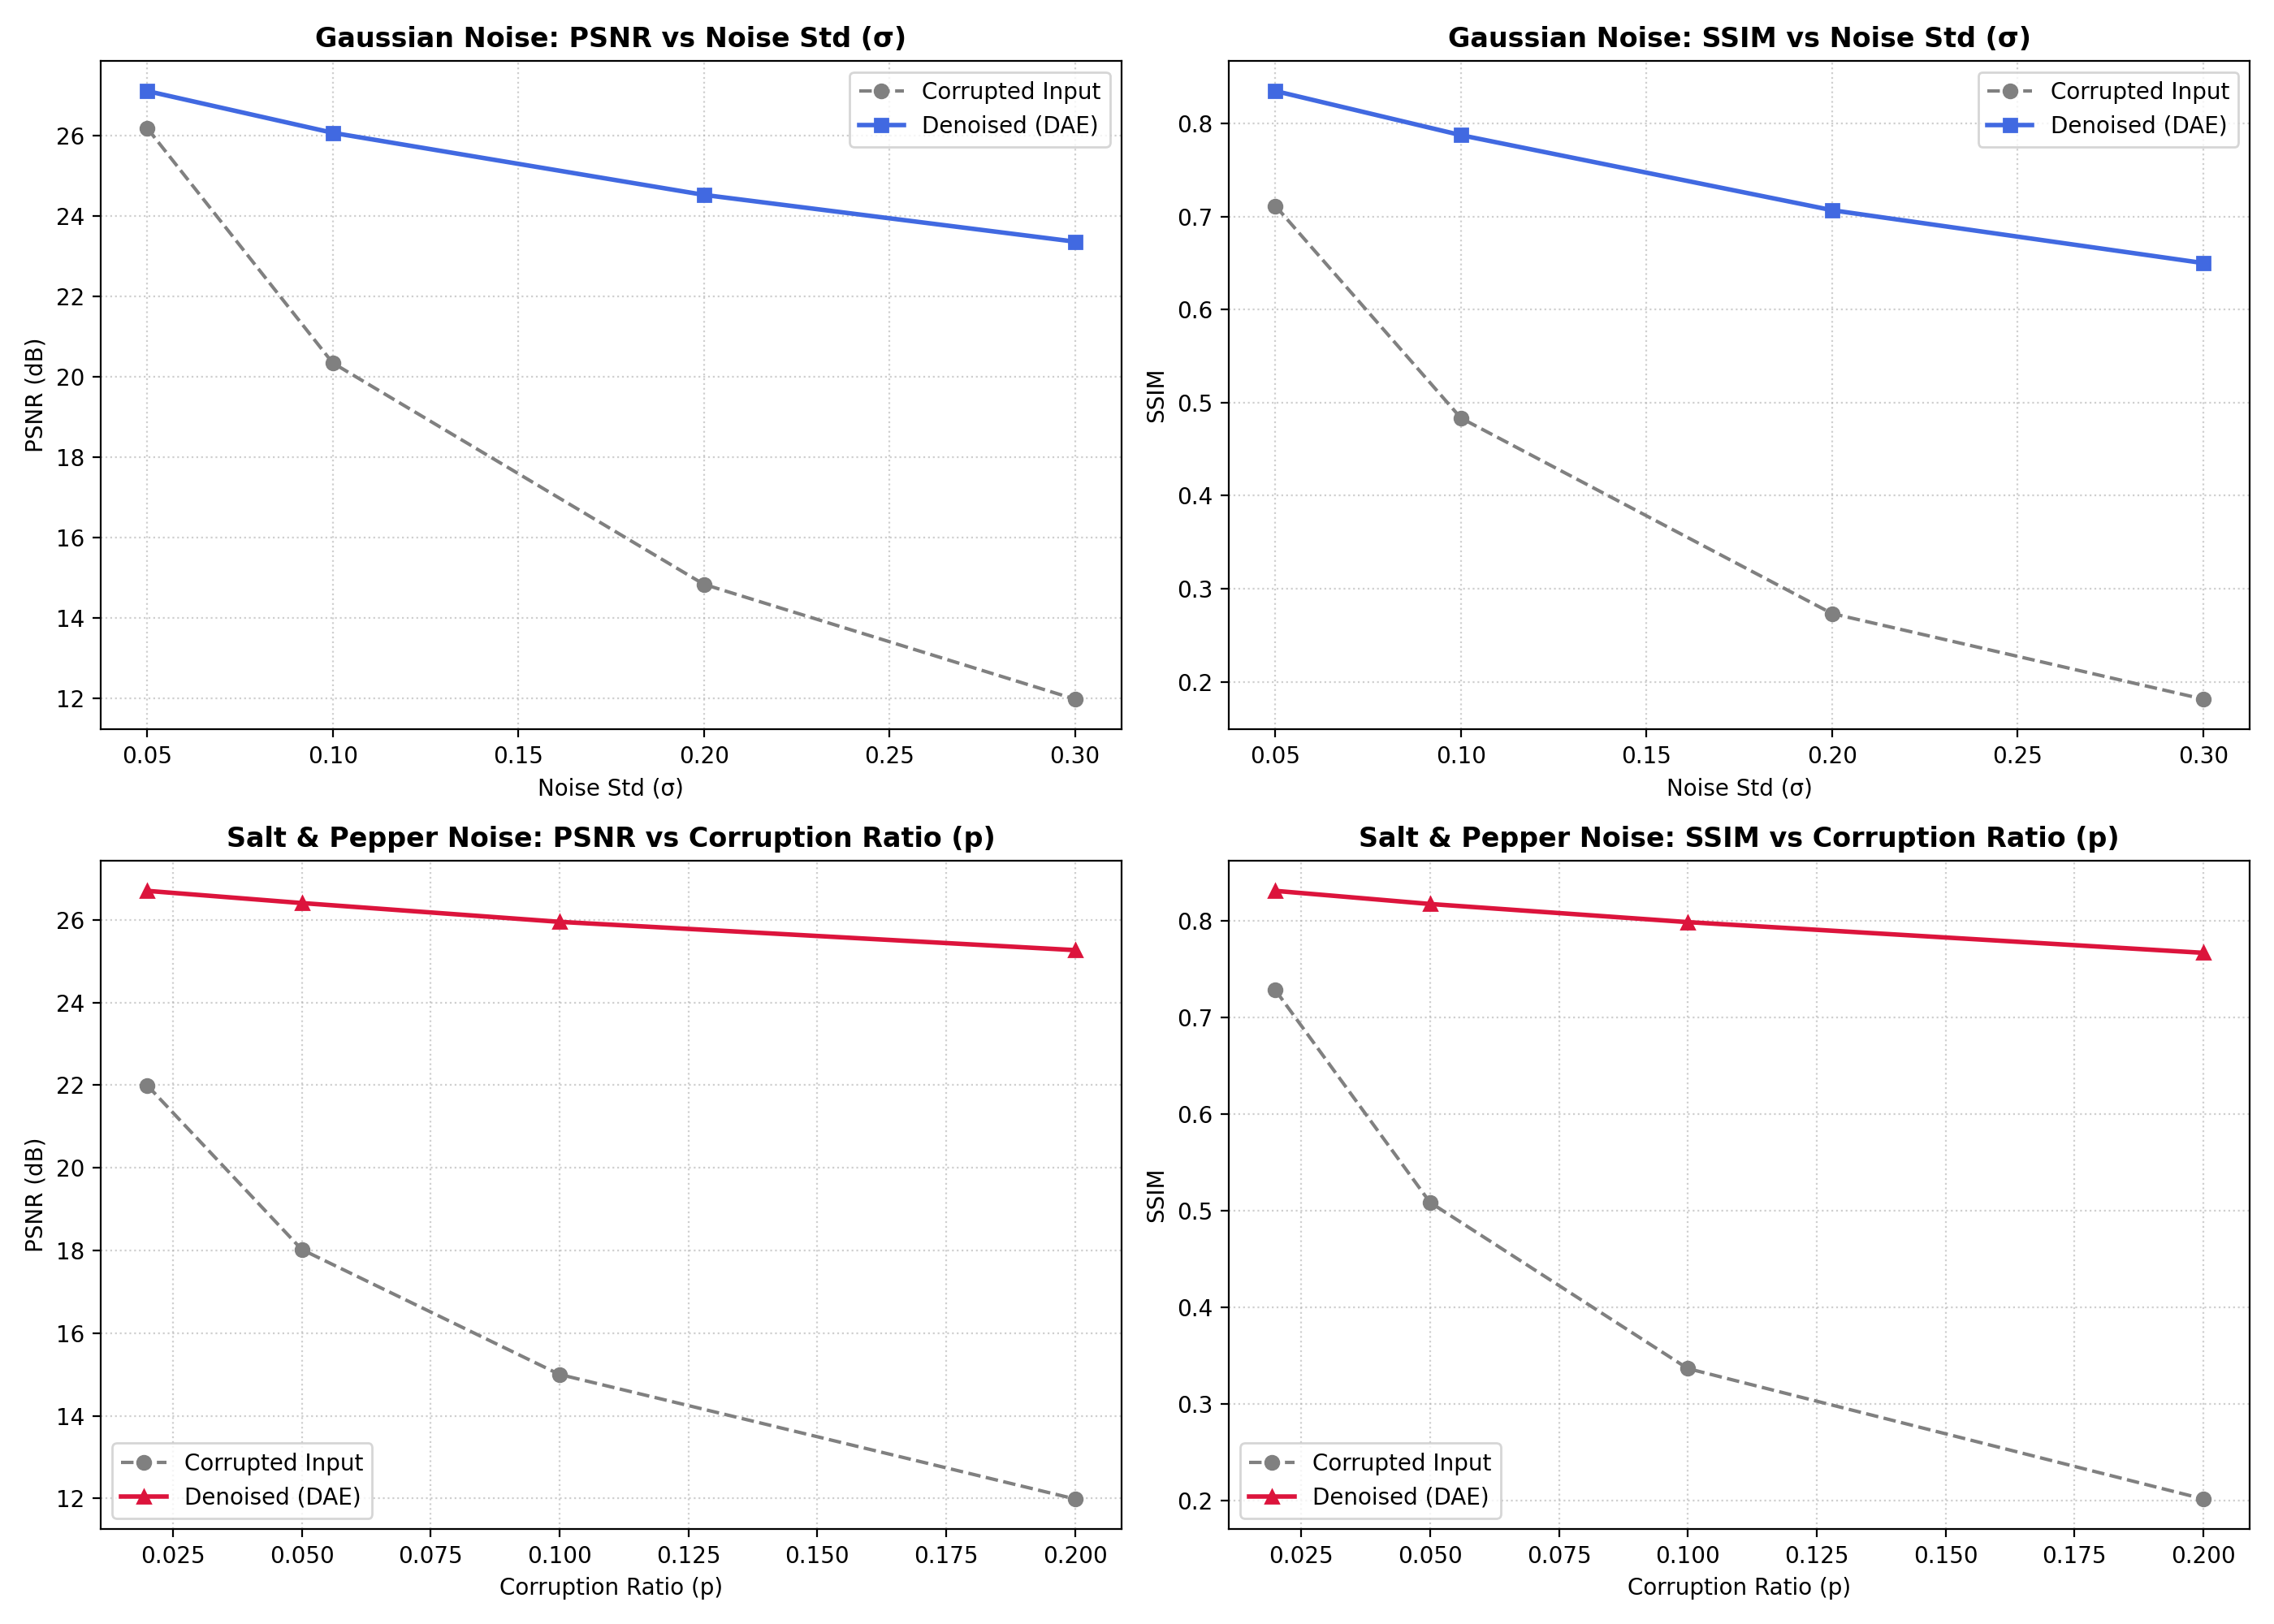

Study 2: Performance vs Bottleneck Capacity:


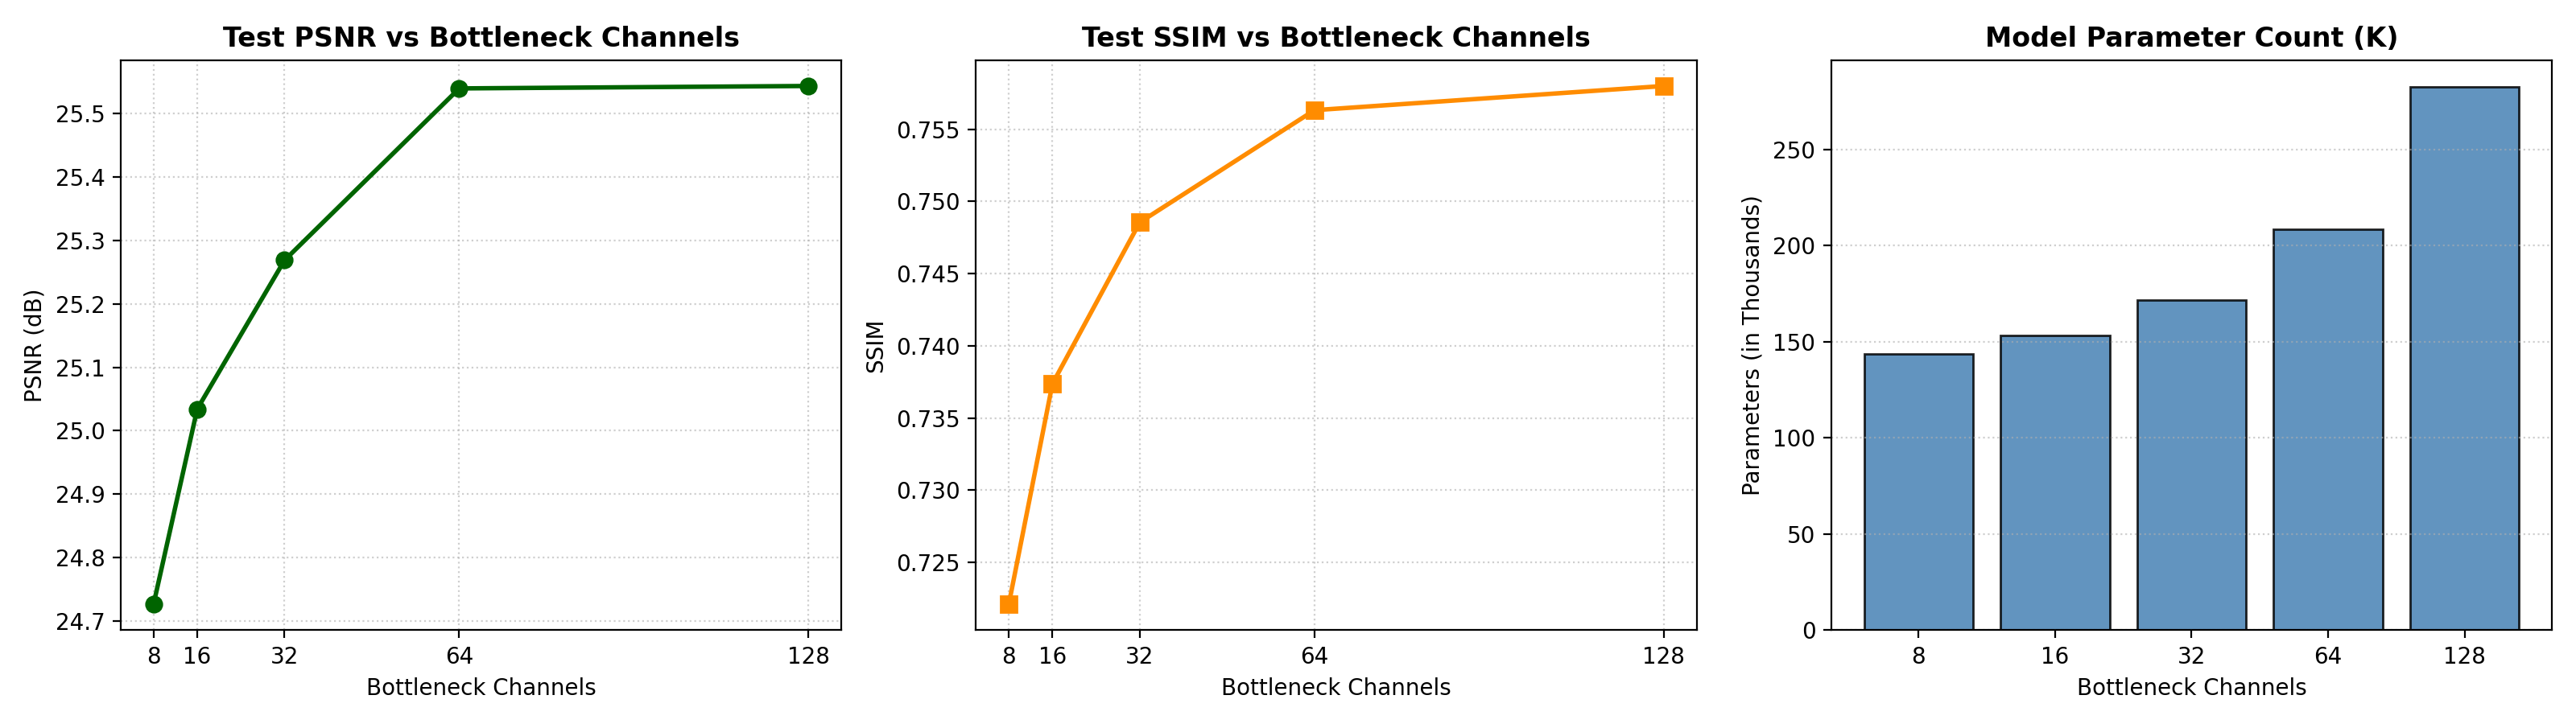

In [22]:
print("Study 1: Performance vs Noise Levels:")
display(Image('./experiments_output/noise_study_curves.png'))

print("Study 2: Performance vs Bottleneck Capacity:")
display(Image('./experiments_output/bottleneck_study_curves.png'))

### View Summary Tables & Report

In [23]:
import pandas as pd
from IPython.display import Markdown

print("--- Noise Study Results Table ---")
df_noise = pd.read_csv('./experiments_output/noise_study_results.csv')
display(df_noise[['Noise Type', 'Noise Level', 'Input PSNR (dB)', 'Output PSNR (dB)', 'Delta PSNR (dB)', 'Output SSIM']])

print("\n--- Bottleneck Study Results Table ---")
df_btn = pd.read_csv('./experiments_output/bottleneck_study_results.csv')
display(df_btn[['Bottleneck Channels', 'Total Parameters', 'Compression Ratio', 'Output PSNR (dB)', 'Output SSIM', 'Delta PSNR (dB)']])

with open('./experiments_output/experimental_study_report.md', 'r') as f:
    display(Markdown(f.read()))

--- Noise Study Results Table ---


,Noise Type,Noise Level,Input PSNR (dB),Output PSNR (dB),Delta PSNR (dB),Output SSIM
0,gaussian,0.05,26.194051,27.116250,0.922198,0.834951
1,gaussian,0.10,20.345626,26.076542,5.730917,0.787531
2,gaussian,0.20,14.833948,24.530720,9.696772,0.706870
3,gaussian,0.30,11.974291,23.365447,11.391156,0.650056
4,salt_and_pepper,0.02,21.996943,26.700685,4.703742,0.830564
5,salt_and_pepper,0.05,18.023319,26.405493,8.382174,0.816980
6,salt_and_pepper,0.10,15.001280,25.950981,10.949701,0.798226
7,salt_and_pepper,0.20,11.988808,25.266826,13.278017,0.766480



--- Bottleneck Study Results Table ---


,Bottleneck Channels,Total Parameters,Compression Ratio,Output PSNR (dB),Output SSIM,Delta PSNR (dB)
0,8,143827,6.00x,24.726261,0.722104,7.670920
1,16,153059,3.00x,25.034181,0.737375,7.978840
2,32,171523,1.50x,25.268910,0.748550,8.213569
3,64,208451,0.75x,25.539877,0.756313,8.484537
4,128,282307,0.38x,25.543700,0.757988,8.488359


# Experimental Study: Image Denoising using Denoising Autoencoder

## Overview

This report summarizes the experimental findings on the Berkeley Segmentation Dataset (BSDS500) evaluating convolutional denoising autoencoders under varying noise intensities and bottleneck capacities.

## 1. Study 1: Reconstruction Performance vs Noise Levels

| Noise Type | Intensity | Input PSNR (dB) | Input SSIM | Output PSNR (dB) | Output SSIM | Δ PSNR (dB) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| gaussian | 0.05 | 26.19 | 0.7115 | **27.12** | **0.8350** | +0.92 |
| gaussian | 0.1 | 20.35 | 0.4834 | **26.08** | **0.7875** | +5.73 |
| gaussian | 0.2 | 14.83 | 0.2733 | **24.53** | **0.7069** | +9.70 |
| gaussian | 0.3 | 11.97 | 0.1814 | **23.37** | **0.6501** | +11.39 |
| salt_and_pepper | 0.02 | 22.00 | 0.7278 | **26.70** | **0.8306** | +4.70 |
| salt_and_pepper | 0.05 | 18.02 | 0.5084 | **26.41** | **0.8170** | +8.38 |
| salt_and_pepper | 0.1 | 15.00 | 0.3366 | **25.95** | **0.7982** | +10.95 |
| salt_and_pepper | 0.2 | 11.99 | 0.2017 | **25.27** | **0.7665** | +13.28 |

**Observations:** _write these from the table above._

## 2. Study 2: Reconstruction Performance vs Bottleneck Capacity

| Bottleneck Channels | Parameters | Compression Ratio | Output PSNR (dB) | Output SSIM | Δ PSNR (dB) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **8** | 143,827 | 6.00x | **24.73** | **0.7221** | +7.67 |
| **16** | 153,059 | 3.00x | **25.03** | **0.7374** | +7.98 |
| **32** | 171,523 | 1.50x | **25.27** | **0.7485** | +8.21 |
| **64** | 208,451 | 0.75x | **25.54** | **0.7563** | +8.48 |
| **128** | 282,307 | 0.38x | **25.54** | **0.7580** | +8.49 |

**Observations:** _write these from the table above._
